In [ ]:
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output
import networkx as nx
import torch
import math

### Spiral Dataset Overview

This dataset comprises spirals, each defined by points in a 2D plane, evolving over time. There are two types of spirals: clockwise and anticlockwise. The challenge is to classify each spiral using Graph Neural Networks (GNNs).

#### Data Structure:

- **Temporal Sequence**: Each point in a spiral corresponds to a time step, forming a sequence.
- **Spiral Types**: Two categories - clockwise (label 0) and anticlockwise (label 1).
- **Dimensions**:
  - **X**: Tensor of shape (batch_size, num_timepoints, 3), where each point is (time, x_pos, y_pos).
  - **y**: Tensor of labels, shape (batch_size,), values 0 or 1.

#### Generation Process:

- **Time Scale**: `t` is linearly spaced between 0 and \( 4\pi \), normalized by \( 4\pi \).
- **Position Calculation**: `x_pos` and `y_pos` are calculated using trigonometric functions. `x_pos` is negated for half the batch to create both spiral types.
- **Noise Addition**: Gaussian noise (std dev = `noise`) is added to positions.

#### Graph Conversion:

- Each spiral is treated as a graph.
- Nodes: Points in the spiral.
- Edges: Connect consecutive points within each spiral.

#### Batch Preparation:

#### Function: `sample_batch()`

- **Purpose**: Generates a batch of spiral data and converts it into a graph format suitable for GNN processing.

#### Process:

1. **Data Generation**:
   - Calls `get_data(batch_size, noise=noise, num_timepoints=num_timepoints)` to generate spiral data.
   - **X**: A tensor of shape `(batch_size, num_timepoints, 3)` containing the time, x, and y coordinates for each point in each spiral.
   - **y**: A tensor of labels of shape `(batch_size,)`, where each label is 0 (clockwise) or 1 (anticlockwise).

2. **Data Flattening**:
   - **X_flat**: Flattens `X` to a shape of `(-1, 3)`, resulting in a tensor where each row represents a node in one of the spirals across the batch. The total number of nodes is `batch_size * num_timepoints`.

3. **Edge Creation**:
   - Constructs edges to connect consecutive nodes within each spiral.
   - Ensures that nodes from different spirals are not interconnected.
   - Results in an edge list `edges`, which is a 2D tensor of shape `(2, num_edges)`, where `num_edges` is the total number of edges across all spirals in the batch.

4. **Label Replication**:
   - **y_flat**: Replicates each label in `y` for each node in the corresponding spiral, resulting in a flat tensor of shape `(-1,)`, aligning with the nodes in `X_flat`.

#### Final Data Shape:

- **X_flat**: Tensor of shape `([batch_size * num_timepoints, 3])`. Each row corresponds to a node (timepoint) in one of the spirals.
- **edges**: Tensor of shape `(2, num_edges)`. Each column is an edge connecting two nodes within the same spiral.
- **y_flat**: Tensor of shape `([batch_size * num_timepoints])`. Each element is the label for the corresponding node in `X_flat`.

This process prepares the dataset the GNN, where each spiral is represented as an individual graph within the batch, and each node within the graph is connected in sequence to form the spiral structure. The labels are expanded to align with the nodes for a node-level classification tasks.

In [ ]:
def get_data(batch_size, num_timepoints=64, noise = 0.05):
    t = torch.linspace(0., 4 * math.pi, num_timepoints)

    start = torch.rand(batch_size) * 2 * math.pi
    x_pos = torch.cos(start.unsqueeze(1) + t.unsqueeze(0)) / (1 + 0.5 * t)
    x_pos[:batch_size//2] *= -1
    y_pos = torch.sin(start.unsqueeze(1) + t.unsqueeze(0)) / (1 + 0.5 * t)
    x_pos += noise * torch.randn_like(x_pos)
    y_pos += noise * torch.randn_like(y_pos)

    X = torch.stack([t.unsqueeze(0).repeat(batch_size, 1)/(4 * math.pi), x_pos, y_pos], dim=2)
    y = torch.zeros(batch_size)
    y[:batch_size//2] = 1

    perm = torch.randperm(batch_size)
    X = X[perm]
    y = y[perm]

    ######################
    # X is a tensor of observations, of shape (batch=128, sequence=100, channels=3)
    # y is a tensor of labels, of shape (batch=128,), either 0 or 1 corresponding to anticlockwise or clockwise
    # respectively.
    ######################
    return X, y

def sample_batch(batch_size, noise=0.05, num_timepoints=64):
    X, y = get_data(batch_size, noise=noise, num_timepoints=num_timepoints)

    num_nodes_per_graph = X.size(1)  # Number of timepoints, acting as nodes
    num_graphs = X.size(0)           # Batch size, each spiral is a separate graph

    # Flatten the data to treat each timepoint as a node
    X_flat = X.view(-1, 3)    # Shape: [num_graphs * num_nodes_per_graph, 3]

    # Corrected edge creation logic
    edges = []
    for i in range(num_graphs):
        for j in range(num_nodes_per_graph - 1):
            # Add edge from node j to node j+1 in graph i
            start_node_idx = i * num_nodes_per_graph + j
            end_node_idx = start_node_idx + 1
            edges.append((start_node_idx, end_node_idx))

    edges = torch.tensor(edges, dtype=torch.long).t().contiguous()

    # Flatten the labels
    y_flat = y.unsqueeze(1).repeat(1, num_nodes_per_graph).view(-1)

    return X_flat, edges, y_flat

This visualization depicts a single spiral from our dataset, showing how its shape evolves over time. The points are plotted in a 2D space, with the x and y coordinates representing their spatial positions. The color gradient indicates the progression of time, offering insights into the spiral's temporal dynamics.

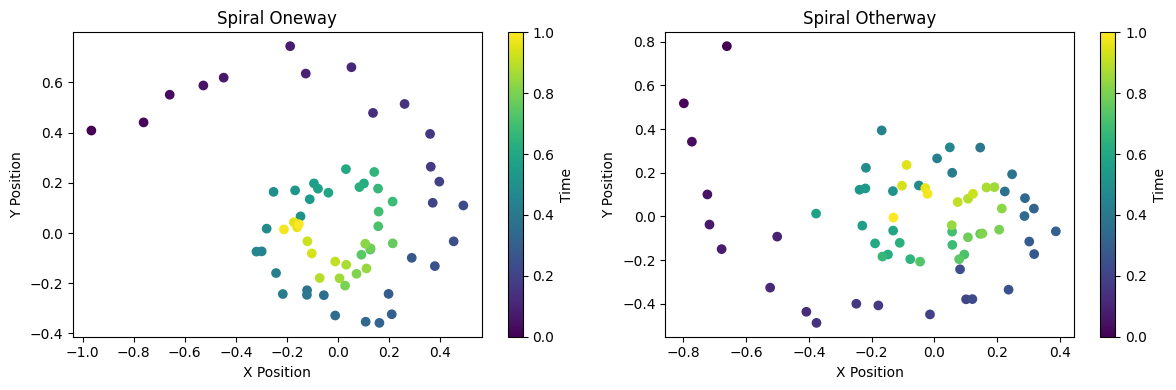

In [ ]:
# Sample a batch with two spirals for visualization
X, _ = get_data(batch_size=2)

# Extracting spirals from the batch
spiral_1 = X[0]
spiral_2 = X[1]

# Extracting time, x, and y coordinates for both spirals
t1, x1, y1 = spiral_1[:, 0].numpy(), spiral_1[:, 1].numpy(), spiral_1[:, 2].numpy()
t2, x2, y2 = spiral_2[:, 0].numpy(), spiral_2[:, 1].numpy(), spiral_2[:, 2].numpy()

# Plotting the spirals side by side in 2D with time used for coloring
plt.figure(figsize=(12, 4))

# Spiral 1
plt.subplot(1, 2, 1)
sc1 = plt.scatter(x1, y1, c=t1, cmap='viridis')
plt.colorbar(sc1, label='Time')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.title('Spiral Oneway')

# Spiral 2
plt.subplot(1, 2, 2)
sc2 = plt.scatter(x2, y2, c=t2, cmap='viridis')
plt.colorbar(sc2, label='Time')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.title('Spiral Otherway')

plt.tight_layout()
plt.show()

This visualization showcases two separate spirals from a single batch.

In the plot, both spirals are displayed within the same figure, highlighting that our batch contains multiple graphs. This is a key aspect of our dataset structure: each batch can consist of several individual graphs (spirals), which are processed independently but in parallel. The visualization demonstrates the distinctness of each graph within the batch, showing the ability of graph neural networks to handle multiple graph structures simultaneously.

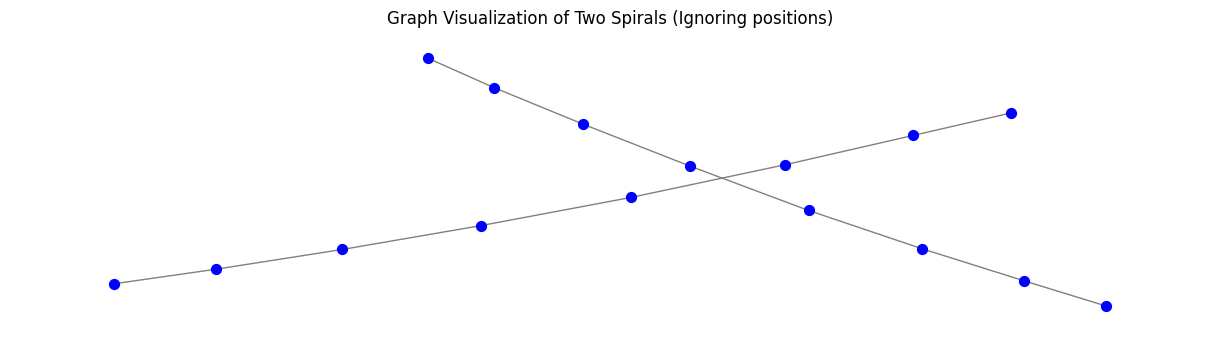

In [ ]:
# Sample a batch with two spirals
X, edges, _ = sample_batch(batch_size=2, num_timepoints = 8)

# Create a NetworkX graph
G = nx.Graph()

# Add edges from the edge tensor
for i in range(edges.shape[1]):
    source, target = edges[:, i].numpy()
    G.add_edge(source, target)

# Define node positions (x, y coordinates)
pos = {i: (X[i, 1].item(), X[i, 2].item()) for i in range(X.shape[0])}

# Plot the graph
plt.figure(figsize=(12, 3))
nx.draw(G, node_size=50, with_labels=False, node_color='blue', edge_color='grey')
plt.title('Graph Visualization of Two Spirals (Ignoring positions)')
plt.show()

### Introduction to GCL_Layer and GCL Classes

#### GCL_Layer Class:
- **Function**: Represents a single Graph Convolutional Layer.
- **Operation**:
  - Processes node features (`h`) and edge information (`edge_index`, `edge_attr`) through a neural network.
  - Uses two MLPs (`edge_mlp` and `node_mlp`) for edge message computation and node feature updates.

#### GCL Class:
- **Function**: Constructs a multi-layer Graph Neural Network.
- **Structure**:
  - Comprises multiple `GCL_Layer` instances, stacked to form a deep GNN.
  - Includes input and output embeddings to map node features to the hidden dimension and back.
- **Flexibility**: Can be configured with a variable number of layers (`n_layers`), enabling customization of network depth.

Both classes work together, with `GCL_Layer` providing the fundamental building block for the graph convolution process, and `GCL` containing multiple such layers to form a complete GNN model capable of handling complex graph-structured data.

### Exercise: Complete the GNN Implementation

**Part 1: Edge Model in GCL_Layer**
- **Task**: Complete the `edge_model` method in the `GCL_Layer` class.
- **Question**: Implement the method to compute the messages between nodes based on node and edge attributes. How does concatenating the source and target node features, along with any edge attributes, contribute to message computation in a graph neural network? What are the required input and output shapes?

**Part 2: Node Model in GCL_Layer**
- **Task**: Complete the `node_model` method in the `GCL_Layer` class.
- **Question**: Write the code to update node attributes based on aggregated messages and previous node features. How does aggregating messages over the edges and concatenating them with the current node features help in updating the node's representation? What are the required input and output shapes?

**Part 3: Forward Method in GCL**
- **Task**: Implement the `forward` method in the `GCL` class.
- **Question**: In the forward pass, how does sequentially applying each `GCL_Layer` and updating the node features with the output from each layer contribute to capturing the dependencies in the graph structure? How does information flow for each layer in the GNN?

In [ ]:
class GCL_Layer(nn.Module):
    """Basic Graph Convolutional Neural Net
    Args:
          hidden_dim: Number of hidden units.
          num_nodes: Maximum number of nodes (for self-attentive pooling).
          global_agg: Global aggregation function ('attn' or 'sum').
          temp: Softmax temperature.
    """

    def __init__(self, input_nf, output_nf, hidden_nf, edges_in_nf=0, act_fn=nn.ReLU(), bias=True):
        super(GCL_Layer, self).__init__()
        #Implement the necessary neural networks here.

    def edge_model(self, source, target, edge_attr):
        """computes the messages between the nodes based on node and edge attributes
        Args:
              source: All the source nodes for each edge in the graph, shape = (edge number, node features)
              target: All the target nodes for each edge in the graph, shape = (edge number, node features)
              edge_attr: Value associated with each edge, type None in tutorial, shape = (edge number, edge features)
        """
        #Implement the message computation here, note, that in our example there are no edge features
        return m

    def node_model(self, h, edge_index, m):
        """Updates the node attributes based on the aggregated messages and previous node features
        Args:
              h: All the nodes in the graph, shape = (node number, node features)
              edge_index: The tensor that denotes the node edges, shape = (2, edge number)
              m: The message computed with the edge model, shape = (edge number, hidden features)
        """
        row, col = edge_index
        agg = unsorted_segment_sum(m, row, num_segments=h.size(0))
        #Implement the update of the node attributes based on the given message aggregation code
        return out

    def forward(self, h, edge_index, edge_attr=None):
        """The full layer forward pass, that encompases message computation and node attribute h update
        Args:
              h: All the nodes in the graph, shape = (node number, node features)
              edge_index: The tensor that denotes the node edges, shape = (2, edge number)
              edge_attr: The message computed with the edge model, shape = (edge number, edge features)
        """
        row, col = edge_index
        #Implement the complete forward pass, hint: the edge model takes the following as input h[row], h[col], edge_attr
        return h

class GCL(nn.Module):
    def __init__(self, in_node_nf, hidden_nf, out_node_nf, in_edge_nf=0, device='cuda', act_fn=nn.ReLU(), n_layers=4):
        super(GCL, self).__init__()
        self.hidden_nf = hidden_nf
        self.device = device
        self.n_layers = n_layers
        self.embedding_in = nn.Linear(in_node_nf, self.hidden_nf)
        self.embedding_out = nn.Linear(self.hidden_nf, out_node_nf)

        for i in range(n_layers):
            self.add_module(f"gcl_{i}", GCL_Layer(self.hidden_nf, self.hidden_nf, self.hidden_nf, in_edge_nf, act_fn=act_fn))

        self.to(self.device)

    def forward(self, h, edge_index, edge_attr=None):
        h = self.embedding_in(h)
        for i in range(self.n_layers):
            h = self._modules[f"gcl_{i}"](h, edges, edge_attr=edge_attr)
        h = self.embedding_out(h)
        return h

def unsorted_segment_sum(data, segment_ids, num_segments):
    """aggregates the messages"""
    result_shape = (num_segments, data.size(1))
    result = data.new_full(result_shape, 0)  # Init empty result tensor.
    segment_ids = segment_ids.unsqueeze(-1).expand(-1, data.size(1))
    result.scatter_add_(0, segment_ids, data)
    return result

In [ ]:
# Example parameters for the EGNN model
in_node_nf = 3  # Number of features for each node in the input
out_node_nf = 1  # Number of features for each node in the output (e.g., for binary classification)
hidden_nf = 16  # Number of hidden features in the GNN layers
in_edge_nf = 0  # Number of features for each edge in the input (set to 0 if there are no edge features)
n_layers = 3    # Number of GNN layers in the model

batch_size = 2
num_batches = 10000

# Instantiate the EGNN model
model = GCL(in_node_nf=in_node_nf,
                  hidden_nf=hidden_nf,
                  out_node_nf=out_node_nf,
                  in_edge_nf=in_edge_nf,
                  n_layers=n_layers,
                  device='cpu')

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001)

### Exercise: Implementing Forward Pass and Loss Calculation in GNN Training

#### Introduction

In this exercise, you will explore the impact of GNN depth on its performance, especially under varying noise conditions. Initially, you will implement a single-layer GNN for both node-level and graph-level classification tasks. Then, you will experiment with a multi-layer GNN and observe the differences in performance.

#### Task 1: Implement Forward Pass and Loss Calculation

* **Objective**: Implement the forward pass and loss calculation in the training loop.
* **Instructions**:

  1. Write code for the forward pass using the model to get the output from the input data (`X_flat` and `edges`).
  2. Implement the loss calculation using a suitable loss function.

#### Task 2: Node-Level Classification

* **Objective**: Perform node-level classification using a one-layer GNN.
* **Instructions**:

  1. Set up the GNN model with only one layer.
  2. Train the model on the dataset.
  3. Evaluate how well the model performs in classifying nodes.

#### Task 3: Graph-Level Classification

* **Objective**: Modify the task to perform graph-level classification using the same one-layer GNN.
* **Instructions**:

  1. Adapt your GNN model, if necessary, for graph-level classification by adding some sort of node aggregation.
  2. Re-train the model and observe its performance on graph-level classification tasks.

#### Task 4: Analysis and Multi-Layer GNN

* **Objective**: Explore the impact of using a multi-layer GNN.
* **Instructions**:

  1. Modify the model to have multiple GNN layers.
  2. Train the model on the same tasks but with increased noise in the data.
  3. Analyze why a single-layer GNN might perform poorly under higher noise conditions in terms of the information flow on the graph.

#### Task 5: Symmetries

* **Objective**: Think about symmetries in GNN design (equivariance/invariance and the symmetry groups that could be included).
* **Instructions**:

  1. What form of equivariance or invariance might help the model learn?
  2. Which form of invariance would make learning impossible for this task?

In [ ]:
import torch
import matplotlib.pyplot as plt

# Assuming sample_batch and other necessary functions and variables are defined
total_loss = 0
losses = []
accuracies = []

for batch_idx in range(num_batches):
    # Sample a batch
    X_flat, edges, y_flat = sample_batch(batch_size)

    # Zero the gradients
    optimizer.zero_grad()

    # Forward pass
    #out =
    # Compute the loss
    #loss =

    # Backward pass
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    if (batch_idx + 1) % 200 == 0:
        clear_output(wait=True)
        avg_loss = total_loss / 200 / out.shape[0]
        losses.append(avg_loss)
        total_loss = 0

        # Calculate accuracy
        with torch.no_grad():
          X_flat, edges, y_flat = sample_batch(batch_size*8)
          out = model.forward(X_flat, edges)

        predicted = (out.data > 0).float()  # Convert logits to binary predictions
        correct = (predicted[:, 0] == y_flat.long()).float().mean()
        accuracies.append(correct)

        # Plotting
        plt.figure(figsize=(14, 5))
        plt.subplot(1, 2, 1)
        plt.plot(losses, label='Loss')
        plt.title('Training Loss')
        plt.xlabel('Batches (x100)')
        plt.ylabel('Loss')
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(accuracies, label='Accuracy')
        plt.title('Test Accuracy')
        plt.xlabel('Batches (x200)')
        plt.ylabel('Accuracy')
        plt.legend()

        plt.show()

KeyboardInterrupt: ignored